# 1. SETUP AND  WEB-SCRAPING 

In [10]:

import json, re, os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import requests
from bs4 import BeautifulSoup

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

RAW_JSON = "bikewale_bikes.json"
BASE = "https://www.bikewale.com"
LIST_URL = (BASE + "/best-bikes-in-india/?sortOrder1=desc&sortField1=modelPopularity"
            "&pageNumber={page}&pageSize=30")
HEADERS = {"user-agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36")}

def find_num(pattern, text, cast=float):
    m = re.search(pattern, text, re.I)
    return cast(m.group(1).replace(",", "")) if m else None

def parse_card(card):
    link = card.find("a", href=True)
    if link is None:
        return None
    name = link.get("title") or link.get_text(strip=True)
    if not name:
        return None
    text = card.get_text(" ", strip=True)
    href = link["href"]
    return {
        "Bike_Name":      name,
        "Price_INR":      find_num(r"₹\s*([\d,]+)", text, int),
        "Rating":         find_num(r"(\d+(?:\.\d+)?)\s*/\s*5", text),
        "Review_Count":   find_num(r"([\d,]+)\s+Ratings?", text, int),
        "Engine_CC":      find_num(r"(\d+(?:\.\d+)?)\s*cc\b", text),
        "Mileage_KMPL":   find_num(r"(\d+(?:\.\d+)?)\s*kmpl\b", text),
        "Power_BHP":      find_num(r"(\d+(?:\.\d+)?)\s*bhp\b", text),
        "Top_Speed_KMPH": find_num(r"(\d+(?:\.\d+)?)\s*kmph\b", text),
        "Range_KM":       find_num(r"(\d+(?:\.\d+)?)\s*km\b", text),
        "Battery_KWh":    find_num(r"(\d+(?:\.\d+)?)\s*kWh\b", text),
        "Weight_KG":      find_num(r"(\d+(?:\.\d+)?)\s*kg\b", text),
        "Detail_URL":     BASE + href if href.startswith("/") else href,
        "Raw_Text":       text,
    }

def get_page(url, retries=3):
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=20)
            if r.status_code == 200:
                return r.text
            print(f"  status {r.status_code}, retry {attempt + 1}")
        except requests.RequestException as e:
            print(f"  error: {e}, retry {attempt + 1}")
        time.sleep(3)
    return None

def scrape_bikewale(max_pages=20, delay=2):
    records, seen = [], set()
    for page_no in range(1, max_pages + 1):
        html = get_page(LIST_URL.format(page=page_no))
        if html is None:
            print(f"Page {page_no}: failed, stopping.")
            break
        cards = BeautifulSoup(html, "html.parser").select("div.o-f7.o-o.o-hA")
        print(f"Page {page_no:>2}: {len(cards)} cards")
        if not cards:                       # empty page = end of listing
            break
        for card in cards:
            rec = parse_card(card)
            if rec and rec["Bike_Name"] not in seen:
                seen.add(rec["Bike_Name"])
                records.append(rec)
        time.sleep(delay)
    return records

# Scrape only if the raw file does not exist yet (set FORCE_SCRAPE = True to scrape again)
FORCE_SCRAPE = False
if FORCE_SCRAPE or not os.path.exists(RAW_JSON):
    data = scrape_bikewale()
    with open(RAW_JSON, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4, ensure_ascii=False)
    print("Scraped", len(data), "records, saved to", RAW_JSON)
else:
    print("Using existing", RAW_JSON)

Using existing bikewale_bikes.json


# DATA UNDERSTANDING AND  CLEANING

In [11]:

df = pd.DataFrame(json.load(open(RAW_JSON, encoding="utf-8")))
df["Popularity_Rank"] = range(1, len(df) + 1)     # site lists models by popularity

print("Raw shape:", df.shape)
print(df.isnull().sum())

log = []                                           # cleaning documentation
def note(issue, action, n): log.append({"Issue": issue, "Action": action, "Rows affected": int(n)})

# text clean-up + duplicates
df["Bike_Name"] = df["Bike_Name"].str.strip().str.replace(r"\s+", " ", regex=True)
d = df.duplicated(subset="Bike_Name").sum()
df = df.drop_duplicates(subset="Bike_Name")
note("Duplicate models", "Dropped duplicates by Bike_Name", d)

# data types
df["Review_Count"] = df["Review_Count"].round().astype("Int64")
note("Review_Count stored as float", "Converted to Int64", df["Review_Count"].notna().sum())

# new columns
df["Brand"] = (df["Detail_URL"].str.extract(r"bikewale\.com/([^/]+?)-bikes/")[0]
               .str.replace("-", " ").str.title()
               .replace({"Tvs": "TVS", "Ktm": "KTM", "Bmw": "BMW", "Royalenfield": "Royal Enfield",
                         "Harleydavidson": "Harley-Davidson"}))
note("No brand column", "Extracted Brand from Detail_URL", df["Brand"].notna().sum())

df["Fuel_Type"] = np.where(df[["Battery_KWh", "Range_KM"]].notna().any(axis=1), "Electric", "Petrol")
note("Petrol and electric mixed", "Created Fuel_Type (Electric if battery/range present)", (df.Fuel_Type == "Electric").sum())

df["Price_Lakh"] = df["Price_INR"] / 1e5
df["Price_Band"] = pd.cut(df["Price_Lakh"], [0, 1, 1.5, 2, 3, 5, np.inf],
                          labels=["<1L", "1-1.5L", "1.5-2L", "2-3L", "3-5L", ">5L"])
note("Price hard to compare", "Created Price_Lakh and Price_Band", len(df))

df["Segment"] = np.select(
    [df.Fuel_Type == "Electric", df.Engine_CC <= 200, df.Engine_CC <= 500, df.Engine_CC > 500],
    ["Electric", "Petrol commuter (up to 200cc)", "Petrol mid (201-500cc)", "Petrol premium (above 500cc)"],
    default="Petrol (cc unknown)")
note("Market mixes small commuter bikes and Rs 10-100 lakh superbikes",
     "Created Segment (Electric / commuter / mid / premium) so comparisons are like-for-like", len(df))

# missing values
note("Battery/Range/Top speed empty for petrol; Engine/Mileage empty for EV",
     "Kept as NaN (attribute does not apply, imputing would create false data)",
     df[["Battery_KWh", "Range_KM", "Top_Speed_KMPH", "Engine_CC", "Mileage_KMPL"]].isna().any(axis=1).sum())
note("Rating/Review_Count missing (new models)",
     "Kept as NaN; rating analysis uses rated models only", df["Rating"].isna().sum())

# outliers
q1, q3 = df.Price_INR.quantile([.25, .75]); iqr = q3 - q1
note("Very expensive models (price outliers)",
     "Kept (genuine superbikes); medians and segments used in analysis", (df.Price_INR > q3 + 1.5 * iqr).sum())

# drop helper column, save
df = df.drop(columns=["Raw_Text"])
note("Raw_Text only needed for extraction", "Dropped", len(df))

df.to_csv("bikewale_cleaned.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(log).to_csv("cleaning_log.csv", index=False)
print("\nCleaned shape:", df.shape)
pd.DataFrame(log)

Raw shape: (446, 14)
Bike_Name            0
Price_INR            0
Rating              35
Review_Count        35
Engine_CC          108
Mileage_KMPL       176
Power_BHP          118
Top_Speed_KMPH     339
Range_KM           337
Battery_KWh        338
Weight_KG           29
Detail_URL           0
Raw_Text             0
Popularity_Rank      0
dtype: int64

Cleaned shape: (446, 18)


,Issue,Action,Rows affected
0,Duplicate models,Dropped duplicates by Bike_Name,0
1,Review_Count stored as float,Converted to Int64,411
2,No brand column,Extracted Brand from Detail_URL,446
3,Petrol and electric mixed,Created Fuel_Type (Electric if battery/range p...,109
4,Price hard to compare,Created Price_Lakh and Price_Band,446
5,Market mixes small commuter bikes and Rs 10-10...,Created Segment (Electric / commuter / mid / p...,446
6,Battery/Range/Top speed empty for petrol; Engi...,"Kept as NaN (attribute does not apply, imputin...",446
7,Rating/Review_Count missing (new models),Kept as NaN; rating analysis uses rated models...,35
8,Very expensive models (price outliers),Kept (genuine superbikes); medians and segment...,39
9,Raw_Text only needed for extraction,Dropped,446


# DATA DICTIONARY

In [12]:

dd = pd.DataFrame([
 ("Popularity_Rank", "Rank on BikeWale popularity list (1 = most popular)", "int"),
 ("Bike_Name",       "Model name", "text"),
 ("Brand",           "Manufacturer (from URL)", "text"),
 ("Fuel_Type",       "Electric or Petrol", "category"),
 ("Price_INR",       "Listed price in rupees", "int"),
 ("Price_Lakh",      "Price in lakhs (1 lakh = 100,000)", "float"),
 ("Price_Band",      "Price group: <1L, 1-1.5L, 1.5-2L, 2-3L, 3-5L, >5L", "category"),
 ("Rating",          "User rating out of 5", "float"),
 ("Review_Count",    "Number of user ratings", "Int64"),
 ("Engine_CC",       "Engine size in cc (petrol)", "float"),
 ("Mileage_KMPL",    "Claimed mileage km/l (petrol)", "float"),
 ("Power_BHP",       "Maximum power in bhp", "float"),
 ("Top_Speed_KMPH",  "Top speed km/h (mostly electric)", "float"),
 ("Range_KM",        "Claimed range per charge in km (electric)", "float"),
 ("Battery_KWh",     "Battery capacity in kWh (electric)", "float"),
 ("Weight_KG",       "Weight in kg", "float"),
 ("Segment",         "Electric / Petrol commuter (up to 200cc) / mid (201-500cc) / premium (above 500cc)", "category"),
 ("Detail_URL",      "Link to model page on BikeWale", "text")],
 columns=["Column", "Description", "Type"])

dd["Missing %"] = dd["Column"].map(lambda c: round(df[c].isna().mean() * 100, 1))
assert set(dd.Column) == set(df.columns), set(dd.Column) ^ set(df.columns)
dd.to_csv("data_dictionary.csv", index=False)
dd

,Column,Description,Type,Missing %
0,Popularity_Rank,Rank on BikeWale popularity list (1 = most pop...,int,0.0
1,Bike_Name,Model name,text,0.0
2,Brand,Manufacturer (from URL),text,0.0
3,Fuel_Type,Electric or Petrol,category,0.0
4,Price_INR,Listed price in rupees,int,0.0
5,Price_Lakh,"Price in lakhs (1 lakh = 100,000)",float,0.0
6,Price_Band,"Price group: <1L, 1-1.5L, 1.5-2L, 2-3L, 3-5L, >5L",category,0.0
7,Rating,User rating out of 5,float,7.8
8,Review_Count,Number of user ratings,Int64,7.8
9,Engine_CC,Engine size in cc (petrol),float,24.2


# Exploratory data analysis (EDA)

In [13]:
print("SUMMARY STATISTICS")
print(df.describe().T.round(2))

print("\nMODELS BY FUEL TYPE\n", df.Fuel_Type.value_counts())
print("\nTOP 10 BRANDS BY MODEL COUNT\n", df.Brand.value_counts().head(10))
print("\nMODELS BY PRICE BAND\n", df.Price_Band.value_counts().sort_index())

r = df.dropna(subset=["Rating"]); r = r[r.Review_Count >= 10]     # ratings from 10+ reviews only
seg_tab = df.groupby("Segment").agg(models=("Bike_Name", "count"),
                                    median_price_lakh=("Price_Lakh", "median")).round(2)
seg_tab["median_rating"] = r.groupby("Segment").Rating.median().round(2)
print("\nSEGMENT SUMMARY\n", seg_tab)

print("\nSPEARMAN CORRELATIONS (all models)")
print(df[["Price_INR", "Rating", "Engine_CC", "Mileage_KMPL", "Power_BHP", "Battery_KWh", "Range_KM"]]
      .corr(method="spearman").round(2))
print("\nNote: price vs mileage is strongly negative mainly because superbikes (high price, low mileage) "
      "are mixed with commuters, so the segments are compared separately above.")

SUMMARY STATISTICS
                 count           mean             std      min       25%  \
Price_INR        446.0  655070.486547  1028963.256213  47922.0  115312.5   
Rating           411.0       4.298297        0.639185      1.7       4.1   
Review_Count     411.0      264.16545      667.796874      1.0       6.5   
Engine_CC        338.0      530.36716      460.045581     49.9   156.225   
Mileage_KMPL     270.0      34.528481       15.255974     12.0    21.325   
Power_BHP        328.0      54.406433       51.780336     4.29   14.7125   
Top_Speed_KMPH   107.0      76.042056       33.047288     25.0      56.5   
Range_KM         109.0      155.33945       86.018756     60.0     100.0   
Battery_KWh      108.0       3.568852        2.217133      0.6     2.275   
Weight_KG        417.0     164.956595       57.182888     45.0     118.0   
Popularity_Rank  446.0          223.5      128.893367      1.0    112.25   
Price_Lakh       446.0       6.550705       10.289633  0.47922  1.153

# Visualizations and dashboard

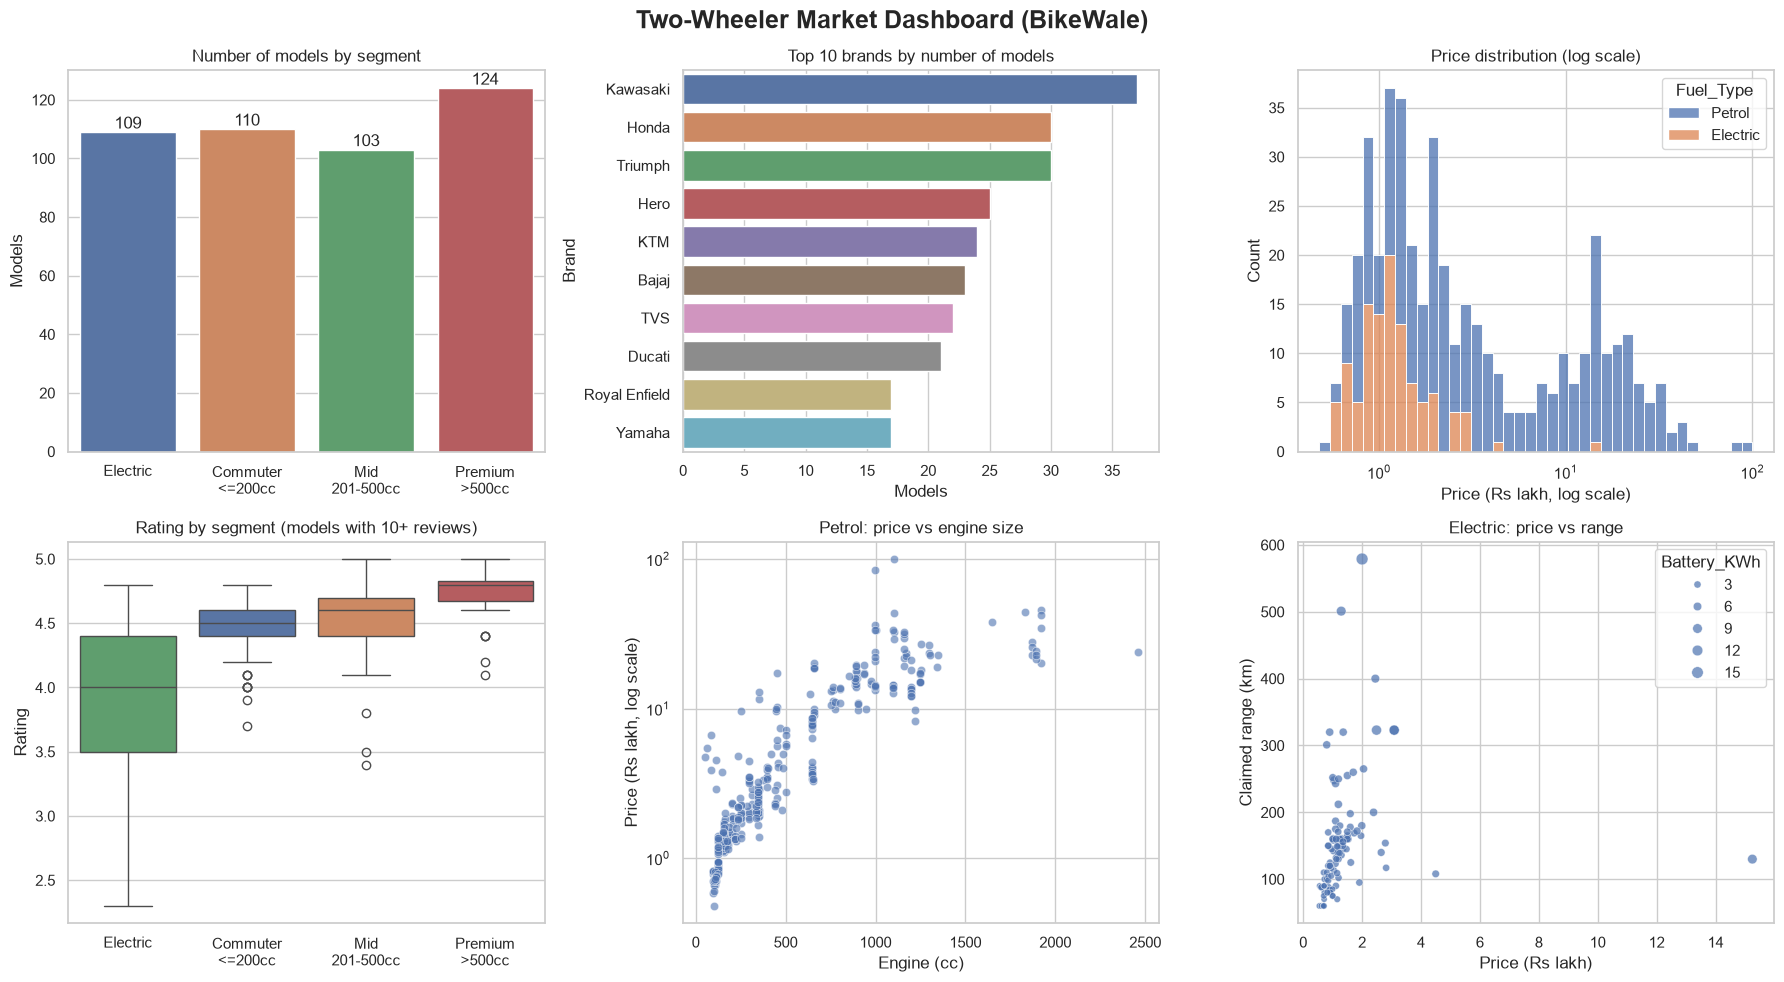

In [14]:
order = ["Electric", "Petrol commuter (up to 200cc)", "Petrol mid (201-500cc)", "Petrol premium (above 500cc)"]
short = {"Electric": "Electric", "Petrol commuter (up to 200cc)": "Commuter\n<=200cc",
         "Petrol mid (201-500cc)": "Mid\n201-500cc", "Petrol premium (above 500cc)": "Premium\n>500cc"}
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

sc = df.Segment.value_counts().reindex(order).dropna()
sns.barplot(x=[short[s] for s in sc.index], y=sc.values, hue=[short[s] for s in sc.index], legend=False, ax=ax[0, 0])
for c in ax[0, 0].containers: ax[0, 0].bar_label(c)
ax[0, 0].set_title("Number of models by segment"); ax[0, 0].set_xlabel(""); ax[0, 0].set_ylabel("Models")

top = df.Brand.value_counts().head(10)
sns.barplot(x=top.values, y=top.index, hue=top.index, legend=False, ax=ax[0, 1])
ax[0, 1].set_title("Top 10 brands by number of models"); ax[0, 1].set_xlabel("Models")

sns.histplot(data=df, x="Price_Lakh", hue="Fuel_Type", multiple="stack", bins=40, log_scale=True, ax=ax[0, 2])
ax[0, 2].set_title("Price distribution (log scale)"); ax[0, 2].set_xlabel("Price (Rs lakh, log scale)")

rt = df.dropna(subset=["Rating"]); rt = rt[rt.Review_Count >= 10]
seg_order = [o for o in order if o in rt.Segment.unique()]
sns.boxplot(data=rt, x="Segment", y="Rating", order=seg_order, hue="Segment", legend=False, ax=ax[1, 0])
ax[1, 0].set_xticks(range(len(seg_order))); ax[1, 0].set_xticklabels([short[o] for o in seg_order])
ax[1, 0].set_title("Rating by segment (models with 10+ reviews)"); ax[1, 0].set_xlabel("")

p = df[df.Fuel_Type == "Petrol"].dropna(subset=["Engine_CC"])
sns.scatterplot(data=p, x="Engine_CC", y="Price_Lakh", alpha=.6, ax=ax[1, 1]); ax[1, 1].set_yscale("log")
ax[1, 1].set_title("Petrol: price vs engine size"); ax[1, 1].set_xlabel("Engine (cc)"); ax[1, 1].set_ylabel("Price (Rs lakh, log scale)")

e = df[df.Fuel_Type == "Electric"].dropna(subset=["Range_KM"])
sns.scatterplot(data=e, x="Price_Lakh", y="Range_KM", size="Battery_KWh", alpha=.7, ax=ax[1, 2])
ax[1, 2].set_title("Electric: price vs range"); ax[1, 2].set_xlabel("Price (Rs lakh)"); ax[1, 2].set_ylabel("Claimed range (km)")

fig.suptitle("Two-Wheeler Market Dashboard (BikeWale)", fontsize=18, fontweight="bold")
fig.tight_layout(); fig.savefig("charts/dashboard.png", dpi=150); plt.show()

# Business insights and recommendations 

In [16]:
EV, COM, MID, PRE = "Electric", "Petrol commuter (up to 200cc)", "Petrol mid (201-500cc)", "Petrol premium (above 500cc)"
r = df.dropna(subset=["Rating"]); r = r[r.Review_Count >= 10]          # ratings from 10+ reviews only
med_price = df.groupby("Segment").Price_Lakh.median()
med_rate  = r.groupby("Segment").Rating.median()
ev_gap = med_rate[COM] - med_rate[EV]                                    # rating gap: commuter petrol minus EV

# price vs rating: overall and inside each segment
rho_all = r[["Price_INR", "Rating"]].corr(method="spearman").iloc[0, 1]
within = []
for s, g in r.groupby("Segment"):
    if len(g) >= 15:
        within.append(g[["Price_INR", "Rating"]].corr(method="spearman").iloc[0, 1])
rho_in = float(np.nanmean(within)) if within else float("nan")

# brands that serve the everyday market (EV + commuter petrol)
daily = r[r.Segment.isin([EV, COM])]
bg = daily.groupby("Brand").agg(n=("Rating", "size"), rating=("Rating", "mean")).query("n >= 3").sort_values("rating", ascending=False)
daily_all = df[df.Segment.isin([EV, COM])]
band = daily_all.Price_Band.value_counts()

e = df[df.Fuel_Type == "Electric"].dropna(subset=["Range_KM"])
cheap_ev = e.assign(per_km=e.Price_INR / e.Range_KM).nsmallest(3, "per_km").Bike_Name.tolist()
mil = df[df.Segment == COM].dropna(subset=["Mileage_KMPL"]).nlargest(3, "Mileage_KMPL").Bike_Name.tolist()
big = df.Brand.value_counts()
top_brands_txt = ", ".join(f"{b} ({v:.2f})" for b, v in bg.rating.head(3).items()) if len(bg) else "not enough data"

if abs(rho_in) < 0.2 and rho_all >= 0.3:
    seg_msg = "The overall link comes mostly from premium segments being rated higher, not from price itself: inside a segment a higher price does not buy a clearly better rating."
elif abs(rho_in) < 0.2:
    seg_msg = "Price has little link with rating, so a higher price does not guarantee higher satisfaction."
elif rho_in > 0:
    seg_msg = "Higher-priced models tend to be rated higher even inside segments, so price and perceived quality move together."
else:
    seg_msg = "Higher-priced models tend to be rated lower inside segments, so a premium price is not rewarded with satisfaction."
ev_price_msg = ("EVs are price-competitive with petrol commuters." if abs(med_price[EV] / med_price[COM] - 1) <= 0.15
                else "EVs are priced noticeably higher than petrol commuters." if med_price[EV] > med_price[COM] else "EVs are priced noticeably lower than petrol commuters.")
insights = f"""
KEY INSIGHTS
1. Market: {len(df)} models from {df.Brand.nunique()} brands. Electric = {(df.Segment==EV).mean():.0%}, commuter petrol = {(df.Segment==COM).mean():.0%}, mid = {(df.Segment==MID).mean():.0%}, premium (above 500cc) = {(df.Segment==PRE).mean():.0%} of models. {big.index[0]} lists the most models ({big.iloc[0]}).
2. The market has two very different halves: median price is Rs {med_price[COM]:.2f}L for commuters vs Rs {med_price[PRE]:.2f}L for premium bikes, so overall averages are misleading and segments are compared separately.
3. Like-for-like price: electric Rs {med_price[EV]:.2f}L vs commuter petrol Rs {med_price[COM]:.2f}L ({med_price[EV]/med_price[COM]-1:+.0%}); {ev_price_msg}
4. Satisfaction gap: median rating is {med_rate[EV]:.2f} for EVs vs {med_rate[COM]:.2f} for commuter petrol bikes (gap {ev_gap:+.2f}); mid = {med_rate[MID]:.2f}, premium = {med_rate[PRE]:.2f}.
5. Price vs rating: overall Spearman correlation = {rho_all:.2f}; inside the segments it averages {rho_in:.2f}. {seg_msg}
6. Everyday market (EV + commuter petrol): most crowded price band is {band.idxmax()} ({band.max()/len(daily_all):.0%} of these models). Highest-rated brands here (3+ models, 10+ reviews): {top_brands_txt}.
7. Best-value EVs (lowest Rs per km of claimed range): {', '.join(cheap_ev)}.
8. Best claimed mileage among commuter petrol bikes: {', '.join(mil)}.

RECOMMENDATIONS
1. Plan, price and benchmark each segment separately; never compare a commuter with a superbike.
2. {"Close the EV satisfaction gap: EVs are priced like petrol commuters but rated " + format(ev_gap, ".2f") + " stars lower, so invest in reliability, software and after-sales service before cutting price further." if ev_gap >= 0.2 else "EV ratings are in line with petrol commuters, so EVs can compete mainly on price and range."}
3. Price new EVs at or below the cost-per-km-range of {cheap_ev[0]} to win on value.
4. In the everyday market, the {band.idxmax()} band is the most crowded; differentiate on features and service there, or look for gaps in the neighbouring bands.
5. Learn from the best-rated everyday brands ({', '.join(bg.index[:2]) if len(bg) else 'n/a'}) when setting service and quality standards.
6. Models with fewer than 10 reviews have unreliable ratings; run review campaigns for new launches.
7. Re-run the scraper monthly to track price changes and EV adoption.

LIMITATIONS: one website, one date; listed prices are not on-road prices; popularity is BikeWale's ranking, not sales; ratings are self-selected (enthusiast buyers of premium bikes may rate more generously); claimed range/mileage is not real-world.
"""
print(insights)
open("business_insights.txt", "w", encoding="utf-8").write(insights)


KEY INSIGHTS
1. Market: 446 models from 58 brands. Electric = 24%, commuter petrol = 25%, mid = 23%, premium (above 500cc) = 28% of models. Kawasaki lists the most models (37).
2. The market has two very different halves: median price is Rs 1.16L for commuters vs Rs 15.02L for premium bikes, so overall averages are misleading and segments are compared separately.
3. Like-for-like price: electric Rs 1.12L vs commuter petrol Rs 1.16L (-3%); EVs are price-competitive with petrol commuters.
4. Satisfaction gap: median rating is 4.00 for EVs vs 4.50 for commuter petrol bikes (gap +0.50); mid = 4.60, premium = 4.80.
5. Price vs rating: overall Spearman correlation = 0.51; inside the segments it averages 0.26. Higher-priced models tend to be rated higher even inside segments, so price and perceived quality move together.
6. Everyday market (EV + commuter petrol): most crowded price band is 1-1.5L (41% of these models). Highest-rated brands here (3+ models, 10+ reviews): KTM (4.60), Yamaha (4

2298